# Oblivious amplification of complex postselected dynamics

The implemented source access $A$ has zero-ancilla block $K\approx e^{-iH}/4$ for the three-spin open chain, $t=1$, $\hbar=1$. This notebook adds an actual ancilla reflection $R=I-2\Pi$ and forward/inverse access calls. $\Pi$ acts as identity on the unknown system input. Integer rounds improve acceptance but do not make this approximation deterministic.

State checks refer to accepted system states before final system readout. The measured exports retain only trials with all five ancillary bits zero. Repeating a trial assumes a fresh, re-preparable input; a single unknown input cannot be copied for free.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit

root = Path.cwd()
if not (root / "src/openquantum/simulation/amplification.py").exists() and (root.parent / "src/openquantum/simulation/amplification.py").exists():
    root = root.parent
if (root / "src/openquantum/simulation/amplification.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum import hamiltonian_simulation as hs
    from openquantum.simulation import qsp_evolution as qe, amplification as aa
    from openquantum.simulation.lcu import postselection_attempts
else:
    sys.path.insert(0, str(root))
    import hamiltonian_simulation as hs
    import qsp_evolution as qe
    import amplification as aa
    from lcu import postselection_attempts

source = qe.build_qsp_evolution(hs.spin_terms(3))
H = hs.dense_hamiltonian(3)
initial = np.eye(8, dtype=complex)[:, 0]
Z0 = hs.pauli_matrix("IIZ")
reflection = aa.zero_ancilla_reflection(3, 8)
print("Success ancillas: wires 3 through 7; data wires are 0 through 2")

Success ancillas: wires 3 through 7; data wires are 0 through 2


## A defined reflection/access schedule

Starting with $A$, each chronological round applies $R,A^\dagger,R,A$ and records a global phase $\pi$, giving $A_r=(-ARA^\dagger R)^r A$. The boxes below summarize those implemented circuit definitions; the exported primitive circuits expand all access/reflection gates. The reflection acts only on ancillary wires.

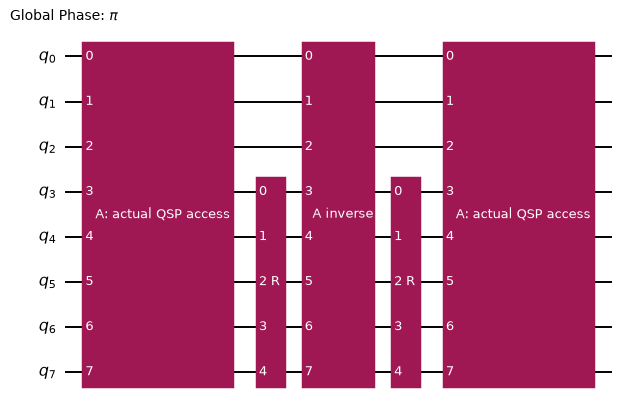

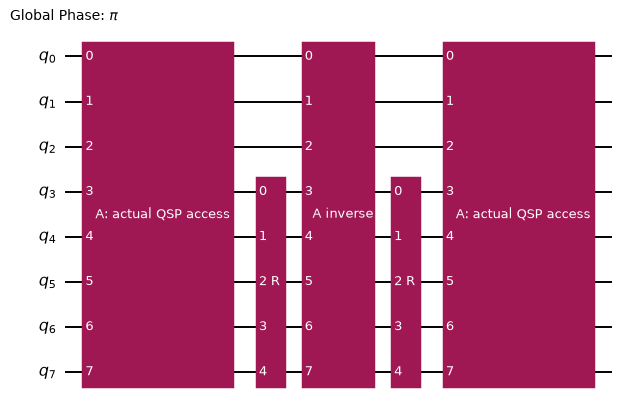

In [2]:
# Extract only the active ancilla instructions from the actual reflection.
ancilla_reflection = QuantumCircuit(5)
for instruction in reflection.data:
    physical = [reflection.find_bit(q).index for q in instruction.qubits]
    assert all(q >= 3 for q in physical)
    ancilla_reflection.append(instruction.operation, [q - 3 for q in physical])
ancilla_reflection.global_phase = reflection.global_phase
schedule = QuantumCircuit(source.num_qubits)
schedule.append(source.to_gate(label="A: actual QSP access"), range(8))
schedule.append(ancilla_reflection.to_gate(label="R"), range(3, 8))
schedule.append(source.inverse().to_gate(label="A inverse"), range(8))
schedule.append(ancilla_reflection.to_gate(label="R"), range(3, 8))
schedule.append(source.to_gate(label="A: actual QSP access"), range(8))
schedule.global_phase += np.pi
schedule.draw(output="mpl", fold=40, scale=.7)

## Exact-model formula and actual circuit checks

If $K=sU$ exactly, $\Pi A_r\Pi=\sin[(2r+1)\arcsin(s)]U$. For $s=1/4$, round 3 has exact-model success $63001/65536\approx0.961319$. The approximate QSP block instead needs its own numerical singular-value, state and observable checks. We simulate every data-basis input to extract the actual accepted block, avoiding an unnecessary full 256-column matrix calculation.

In [3]:
results = []
circuits = {}
for rounds in range(4):
    circuit = aa.build_oblivious_amplification(source, rounds)
    circuits[rounds] = circuit
    result = aa.compare_oblivious_amplification(circuit, H, initial, Z0)
    results.append(result)
rows = [{"rounds": r["rounds"], "A or inverse calls": 2*r["rounds"]+1,
         "reflections": 2*r["rounds"], "ideal-model success": r["ideal_scaled_unitary_success_probability"],
         "actual success": r["actual_input_acceptance_probability"],
         "state-vector error": r["conditional_state_vector_error"],
         "Z error": r["observable_error"]} for r in results]
display(pd.DataFrame(rows))
assert results[-1]["actual_input_acceptance_probability"] < 1
assert results[-1]["conditional_state_vector_error"] < 2e-8

,rounds,A or inverse calls,reflections,ideal-model success,actual success,state-vector error,Z error
0,0,1,0,0.062500,0.062500,6.066764e-09,1.148913e-09
1,1,3,2,0.472656,0.472656,5.433898e-09,7.758389e-10
2,2,5,4,0.908447,0.908447,4.299612e-09,6.204975e-11
3,3,7,6,0.961319,0.961319,4.205062e-09,1.646913e-09


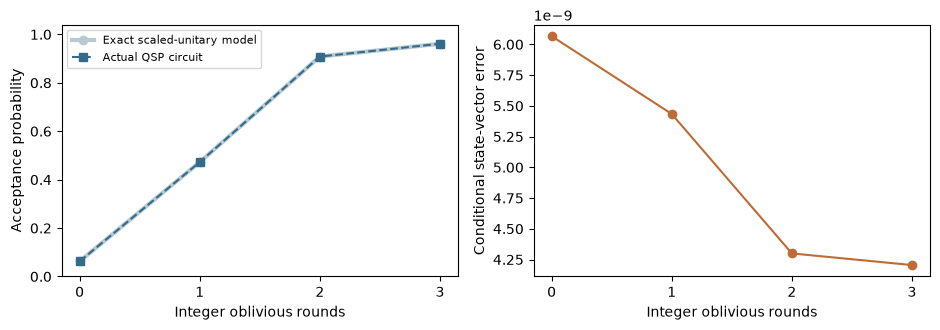

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
rounds = [r["rounds"] for r in results]
axes[0].plot(rounds, [r["ideal_scaled_unitary_success_probability"] for r in results], "o-", label="Exact scaled-unitary model", color="#b7c9d1", lw=3)
axes[0].plot(rounds, [r["actual_input_acceptance_probability"] for r in results], "s--", label="Actual QSP circuit", color="#346b8a")
axes[0].set(xlabel="Integer oblivious rounds", ylabel="Acceptance probability", ylim=(0, 1.04), xticks=rounds)
axes[0].legend(fontsize=8)
axes[1].plot(rounds, [r["conditional_state_vector_error"] for r in results], "o-", color="#be6b35")
axes[1].set(xlabel="Integer oblivious rounds", ylabel="Conditional state-vector error", xticks=rounds)
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0,0))
fig.tight_layout()
plt.show()

## Complete-trial cost and retries

Round 3 uses four forward and three inverse calls to the entire source access, plus six zero-ancilla reflections. Underlying controlled PREPARE/SELECT costs and every final measurement must be included. Higher acceptance trades against longer complete circuits.

The caps below are numerical ideal-instance projections, not certified physical bounds. Accepted-Z sampling and failure of capped retries have separate allocations. Coherent synthesis can change both acceptance and conditional state; physical faults must be allocated over all attempted trials, including rejected ones.

In [5]:
accepted_samples = hs.observable_shots(.03, .005)
workload_rows = []
for result in results:
    pmin = result["finite_H_numerical_minimum_acceptance_probability"]
    one_cap = postselection_attempts(pmin, .01)
    per_sample_cap = postselection_attempts(pmin, .005/accepted_samples)
    workload_rows.append({"rounds": result["rounds"], "cap for one accepted measured trial": one_cap,
                          "accepted Z samples": accepted_samples, "cap attempts per accepted sample": per_sample_cap,
                          "cap complete attempted trials": accepted_samples*per_sample_cap})
display(pd.DataFrame(workload_rows))
compiled = aa.decompose_amplification(circuits[3])
measured = compiled.copy()
measured.measure_all()
display(pd.DataFrame([{"operation": gate, "count per complete round-3 trial": count} for gate,count in measured.count_ops().items()]))
print("Primitive dependency depth:", measured.depth())
print("Numerical acceptance projections certified: False")

,rounds,cap for one accepted measured trial,accepted Z samples,cap attempts per accepted sample,cap complete attempted trials
0,0,72,13315,230,3062450
1,1,8,13315,24,319560
2,2,2,13315,7,93205
3,3,2,13315,5,66575


,operation,count per complete round-3 trial
0,cx,26504
1,rz,14333
2,t,6183
3,tdg,5481
4,ry,4413
5,h,1707
6,x,1385
7,rx,1296
8,measure,8
9,sdg,1


Primitive dependency depth: 46784
Numerical acceptance projections certified: False


## Scope and export phase

The source and tests retain global phases, which matter when an access is coherently controlled. The pinned Qiskit OpenQASM exporter omits an overall circuit phase. Its measured-trial probabilities remain valid, but the downloaded QASM is not a phase-preserving controlled-oracle specification. Use the source modules or restore the recorded phase for coherent reuse.

The source-operation cap counts top-level instructions; nested definitions and transpilation can consume resources before the primitive-export cap is checked. The default source, projected-block simulation and primitive export are bounded and checked. General source complexity is not validated by a top-level count alone.

No inverse channel is used: amplification requires the full unitary access and its inverse. A thermal filter with nonuniform singular values generally changes its target state under oblivious amplification. That method requires a separate distortion/known-input amplification construction. Deterministic amplification, certified rotation synthesis and physical estimates remain planned.